In [1]:
import warnings
import pandas as pd
import plotly.express as px
from data import *

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

ts_user = 'TGa'
gitlab_user = 'tomasz.gac'

:: loading settings :: url = jar:file:/home/daniel.las/work/workspace-crypto/oda/notebooks/venv/lib/python3.8/site-packages/pyspark/jars/ivy-2.5.0.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/daniel.las/.ivy2/cache
The jars for the packages stored in: /home/daniel.las/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
org.apache.spark#spark-avro_2.12 added as a dependency
org.postgresql#postgresql added as a dependency
com.github.jnr#jnr-posix added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-dd4cafde-717c-4e00-ae13-9b9323a1c648;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.2.0 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.2.0 in central
	found com.datastax.oss#java-driver-core-shaded;4.13.0 in central
	found com.datastax.oss#native-protocol;1.5.0 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in local-m2-cache
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhist

# TGa

In [2]:
user_issues(ts_user).toPandas()

25/05/29 12:27:14 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

,key,summary,status,type,priority,size,size_points,status_changed_at,issue_total_hours,user_total_hours
0,CRYP-10723,transaction-verifier loguje błędy,Delivery,Bug,High,None,None,2025-05-28 09:49:14.882,4.0,4.0
1,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,Done,Story,Medium,M,5,2025-05-22 12:38:16.560,103.0,100.5
2,CRYP-10459,[Backtest] Połączenie skryptów do generowania ...,In Review,Story,High,M,5,2025-05-22 12:38:01.669,84.5,84.5
3,CRYP-10079,Rozszerzenie funkcjonalności Platform Admin,To Do,Story,Medium,M,5,2025-05-14 06:36:19.450,12.0,12.0
4,CRYP-9824,[platform-admin] Brak możliwości usuniecią cre...,Delivered,Bug,Medium,XS,1,2025-05-12 10:26:49.298,15.0,6.0
5,CRYP-10666,[Platform Admin] Dodanie btcturk-hft i gateio-...,Delivered,Story,High,XS,1,2025-05-12 10:25:48.556,1.0,1.0
6,CRYP-10232,"[Platform Admin] Błąd ""Bundle com.empirica.alg...",Delivered,Bug,Medium,XS,1,2025-05-12 10:25:38.612,3.5,3.5
7,CRYP-10257,[Backtest] Wykonywanie symulacji dla listy ins...,In Progress,Story,Medium,S,2,2025-04-16 08:10:56.407,15.5,15.5
8,CRYP-10520,[Backtest] Zasilenie danych historycznych od p...,Done,Story,Highest,S,2,2025-04-09 13:37:04.247,34.5,30.5
9,CRYP-10317,Brak liquidity measures dla niektórych instrum...,Done,Bug,High,XS,1,2025-03-12 13:34:28.376,13.0,7.0


In [3]:
user_issues_hours_monthly(ts_user).toPandas()

,month,jira_id,summary,status,hours
0,2025-05-01,CRYP-10257,[Backtest] Wykonywanie symulacji dla listy ins...,In Progress,15.50
1,2025-05-01,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,Done,15.50
2,2025-05-01,CRYP-10459,[Backtest] Połączenie skryptów do generowania ...,In Review,57.50
3,2025-05-01,CRYP-10666,[Platform Admin] Dodanie btcturk-hft i gateio-...,Delivered,1.00
4,2025-05-01,CRYP-10723,transaction-verifier loguje błędy,Delivery,4.00
5,2025-04-01,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,Done,26.00
6,2025-04-01,CRYP-10459,[Backtest] Połączenie skryptów do generowania ...,In Review,27.00
7,2025-04-01,CRYP-10520,[Backtest] Zasilenie danych historycznych od p...,Done,20.00
8,2025-03-01,CRYP-10079,Rozszerzenie funkcjonalności Platform Admin,To Do,5.00
9,2025-03-01,CRYP-10232,"[Platform Admin] Błąd ""Bundle com.empirica.alg...",Delivered,1.50


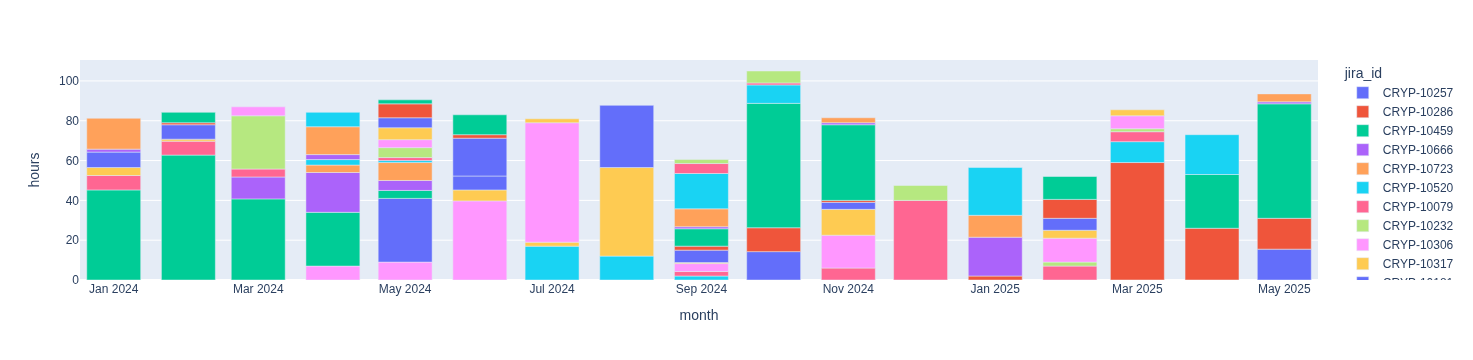

In [4]:
px.bar(user_issues_hours_monthly(ts_user).toPandas(),x='month',y='hours',color='jira_id',hover_data={'summary':True})

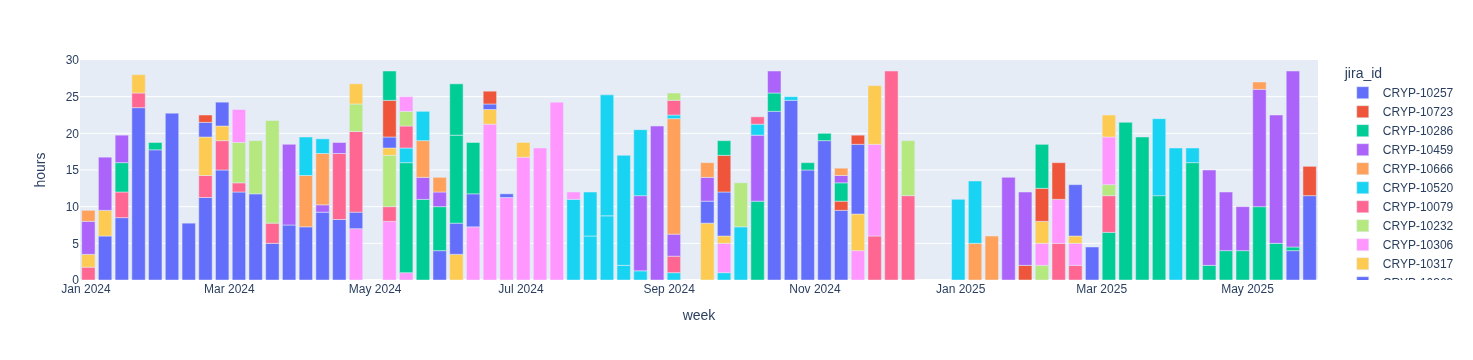

In [5]:
px.bar(user_issues_hours_weekly(ts_user).toPandas(),x='week',y='hours',color='jira_id',hover_data={'summary':True})

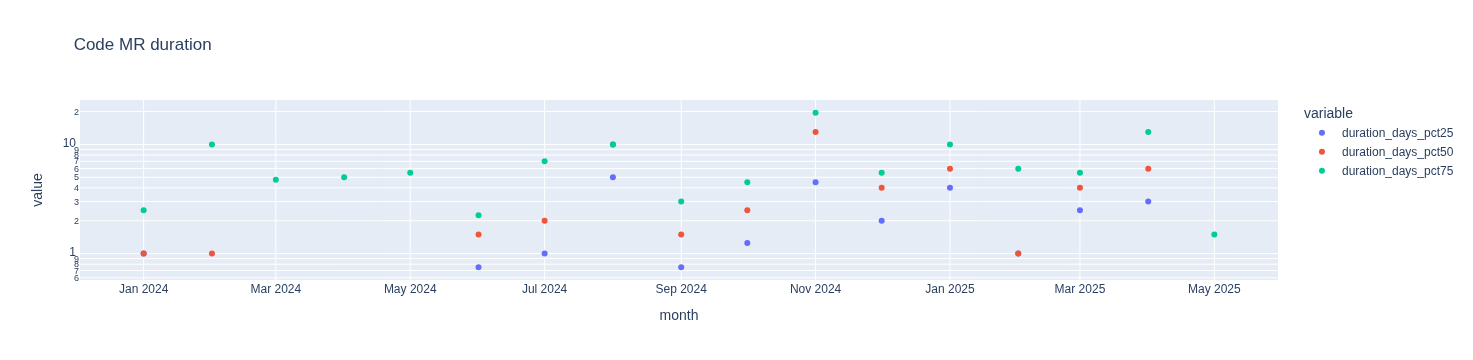

In [6]:
px.scatter(user_mrs_duration(gitlab_user).toPandas(),x='month',y=['duration_days_pct25','duration_days_pct50','duration_days_pct75'], log_y=True,title='Code MR duration')

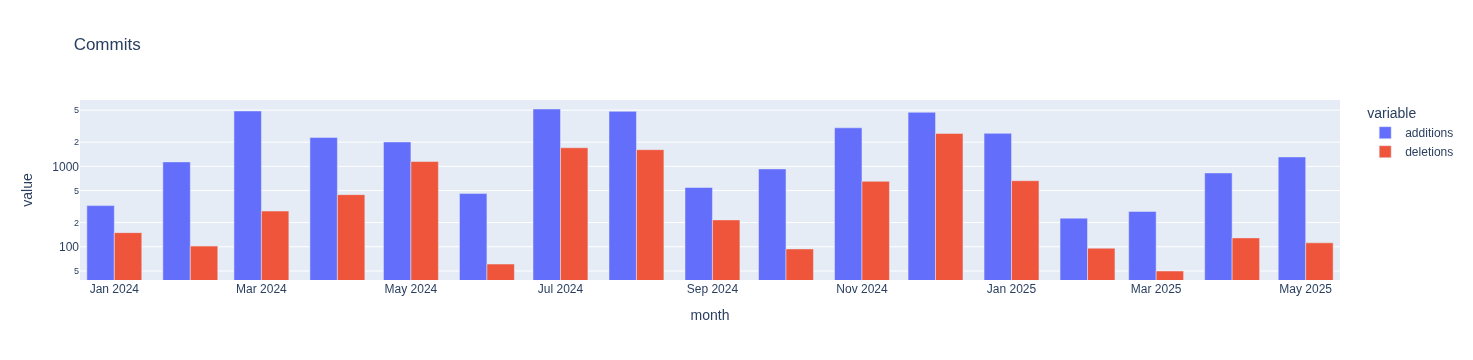

In [7]:
px.bar(user_code_commits(gitlab_user).toPandas(),x='month',y=['additions','deletions'],log_y=True,title='Commits',barmode='group')

In [8]:
users_hours.where(f.col('user')==ts_user).toPandas()

,month,user,jira_hours,other_hours,total_hours,other_hours_pct
0,2025-05-01,TGa,93.50,35.75,129.25,27.659574
1,2025-04-01,TGa,73.00,49.50,122.50,40.408163
2,2025-03-01,TGa,85.50,61.50,147.00,41.836735
3,2025-02-01,TGa,52.00,100.00,152.00,65.789474
4,2025-01-01,TGa,56.50,92.00,148.50,61.952862
5,2024-12-01,TGa,47.50,72.25,119.75,60.334029
6,2024-11-01,TGa,81.50,42.00,123.50,34.008097
7,2024-10-01,TGa,105.00,64.50,169.50,38.053097
8,2024-09-01,TGa,60.50,33.50,94.00,35.638298
9,2024-08-01,TGa,87.75,48.25,136.00,35.477941


In [9]:
user_other_hours(ts_user).toPandas()

,month,task_desc,other_hours
0,2025-05-01,Scrum meetings,9.25
1,2025-05-01,Code review,7.00
2,2025-05-01,Platform configuration,2.50
3,2025-05-01,Team hangouts,2.50
4,2025-05-01,Internal meetings,4.00
5,2025-05-01,MMLAB support,1.00
6,2025-05-01,Research & learning,5.50
7,2025-05-01,Arbitrage presentation,4.00
8,2025-04-01,Scrum meetings,8.00
9,2025-04-01,Internal meetings,6.00
